# Final Project: Line Search, BFGS, and Implicit Runge--Kutta

**MATH-GA 2048 -- Scientific Computing**

**Team members:** Yixia Yu (yy5091@nyu.edu), Yuhong Geng (yg3327@nyu.edu)

This notebook implements the three requested pieces of the final project:

1. a strong-Wolfe line search following Wright--Nocedal Algorithms 3.2--3.3,
2. a BFGS optimizer using that line search and a fourth-order finite-difference
   gradient when no analytic gradient is provided,
3. a two-stage Gauss--Legendre implicit Runge--Kutta solver, tested on the
   forced damped Duffing oscillator.

All floating-point and matrix operations use `numpy`.  Plots and numerical
checks are included after each implementation section.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable, Optional

np.set_printoptions(precision=6, suppress=True)
plt.rcParams['figure.dpi'] = 100


## 1. Strong Wolfe Line Search (Problem 2.1)

### 1.1 Background

Given a current iterate $x_k$ and a descent direction $p_k$ (so $\nabla f(x_k)^\top p_k < 0$),
the line search finds a step length $\alpha_k > 0$ that approximately minimizes

$$
\phi(\alpha) := f(x_k + \alpha p_k), \qquad \phi'(\alpha) = \nabla f(x_k + \alpha p_k)^\top p_k.
$$

The **strong Wolfe conditions** (Wright--Nocedal eq.\ 3.7) are

$$
\phi(\alpha_k) \le \phi(0) + c_1 \alpha_k \phi'(0), \qquad
|\phi'(\alpha_k)| \le c_2\,|\phi'(0)|,
$$

with $0 < c_1 < c_2 < 1$.  The first (Armijo / sufficient decrease) prevents
overshooting; the second (curvature, in strong form) excludes vanishingly
small steps and forces $\alpha_k$ near a local minimum of $\phi$.

The algorithm has two stages.  Stage 1 (Algorithm 3.2) builds a monotonically
increasing sequence $\alpha_1, \alpha_2, \dots$ until either an $\alpha$
satisfying the strong Wolfe conditions is found directly, or one of the
following triggers indicates a bracket has been formed:

(i) Armijo fails at $\alpha_i$, or
(ii) $\phi(\alpha_i) \ge \phi(\alpha_{i-1})$ (function value rebounds), or
(iii) $\phi'(\alpha_i) \ge 0$ (slope turns nonnegative -- we have overshot).

When triggered, Stage 2 (Algorithm 3.3, the `zoom` routine) repeatedly
interpolates inside the bracket $(\alpha_\mathrm{lo}, \alpha_\mathrm{hi})$ until
a strong-Wolfe-feasible point is identified.  The bracket invariants are

(a) the interval contains step lengths satisfying the strong Wolfe conditions,
(b) $\alpha_\mathrm{lo}$ has the smallest $\phi$ among Armijo-feasible trials, and
(c) $\phi'(\alpha_\mathrm{lo})\,(\alpha_\mathrm{hi} - \alpha_\mathrm{lo}) < 0$.

### 1.2 Implementation


In [2]:
def _quadratic_safeguarded(a_lo, a_hi, phi_lo, phi_hi, dphi_lo,
                            edge_frac=0.1):
    # Purpose: choose a trial alpha inside a zoom bracket.
    # Inputs: endpoints, endpoint values, dphi(a_lo), and edge margin.
    span = a_hi - a_lo
    lo, hi = (a_lo, a_hi) if a_lo < a_hi else (a_hi, a_lo)
    bisect = 0.5 * (a_lo + a_hi)
    if abs(span) < 1e-14:
        return bisect  # Output: midpoint fallback.

    denom = 2.0 * (phi_hi - phi_lo - dphi_lo * span)
    if denom <= 0:
        return bisect  # Output: midpoint fallback.

    a_q = a_lo - dphi_lo * span * span / denom
    safe_lo = lo + edge_frac * (hi - lo)
    safe_hi = hi - edge_frac * (hi - lo)
    if a_q < safe_lo or a_q > safe_hi:
        return bisect  # Output: midpoint fallback.
    return a_q  # Output: safeguarded quadratic candidate.


def _zoom(phi, dphi, a_lo, a_hi, phi_lo, phi_hi, dphi_lo,
          phi0, dphi0, c1, c2, counters, max_iter=50):
    # Purpose: shrink a Wolfe bracket until a strong-Wolfe step is found.
    # Inputs: bracket data, phi(0), phi'(0), Wolfe constants, counters.
    for j in range(max_iter):
        a_j = _quadratic_safeguarded(a_lo, a_hi, phi_lo, phi_hi, dphi_lo)
        phi_j = phi(a_j)
        counters['n_phi'] += 1

        # Armijo violation, or no improvement over a_lo: tighten upper bound.
        if (phi_j > phi0 + c1 * a_j * dphi0) or (phi_j >= phi_lo):
            a_hi, phi_hi = a_j, phi_j
            continue

        dphi_j = dphi(a_j)
        counters['n_dphi'] += 1

        if abs(dphi_j) <= -c2 * dphi0:
            return a_j, phi_j, 'wolfe'  # Output: accepted step.

        # Maintain bracket invariant (c) from Algorithm 3.3.
        if dphi_j * (a_hi - a_lo) >= 0:
            a_hi, phi_hi = a_lo, phi_lo

        a_lo, phi_lo, dphi_lo = a_j, phi_j, dphi_j

    return a_lo, phi_lo, 'zoom_maxiter'  # Output: best lower endpoint.


def line_search_wolfe(phi, dphi, c1=1e-4, c2=0.4,
                      alpha_max=10.0, max_iter=25, rho=2.5):
    # Purpose: implement Wright--Nocedal Algorithms 3.2 and 3.3.
    # Inputs: phi, phi', Wolfe constants, max step, iteration cap, growth rho.
    # Output: dict with alpha, phi(alpha), status, and evaluation counts.
    phi0 = phi(0.0)
    dphi0 = dphi(0.0)
    if dphi0 >= 0:
        raise ValueError(f"Direction is not descent: phi'(0) = {dphi0:.3e}")

    counters = {'n_phi': 1, 'n_dphi': 1}
    a_prev, phi_prev, dphi_prev = 0.0, phi0, dphi0
    a_i = min(1.0, alpha_max)   # Standard initial step for quasi-Newton.

    for i in range(1, max_iter + 1):
        phi_i = phi(a_i)
        counters['n_phi'] += 1

        if (phi_i > phi0 + c1 * a_i * dphi0) or (phi_i >= phi_prev and i > 1):
            a_star, phi_star, status = _zoom(
                phi, dphi, a_prev, a_i, phi_prev, phi_i, dphi_prev,
                phi0, dphi0, c1, c2, counters)
            return {'alpha': a_star, 'phi': phi_star,
                    'status': status, **counters}

        dphi_i = dphi(a_i)
        counters['n_dphi'] += 1

        if abs(dphi_i) <= -c2 * dphi0:
            return {'alpha': a_i, 'phi': phi_i, 'status': 'wolfe', **counters}

        if dphi_i >= 0:
            a_star, phi_star, status = _zoom(
                phi, dphi, a_i, a_prev, phi_i, phi_prev, dphi_i,
                phi0, dphi0, c1, c2, counters)
            return {'alpha': a_star, 'phi': phi_star,
                    'status': status, **counters}

        a_prev, phi_prev, dphi_prev = a_i, phi_i, dphi_i
        if a_i >= alpha_max - 1e-14:
            return {'alpha': a_i, 'phi': phi_i, 'status': 'alphamax', **counters}
        a_i = min(rho * a_i, alpha_max)

    return {'alpha': a_i, 'phi': phi_i, 'status': 'stage1_maxiter', **counters}


### 1.3 Sanity test on a 1D quadratic

We verify on $\phi(\alpha) = (\alpha - 2)^2 + 0.5$, whose unique minimum is
at $\alpha^* = 2$ with $\phi(2) = 0.5$ and $\phi'(2) = 0$.

This test also illustrates an important point from Chapter 3: the strong Wolfe
conditions do **not** require the exact one-dimensional minimizer.  With the
main project choice $c_2=0.4$, the step $\alpha=2.5$ is acceptable because its
slope is small enough in magnitude.  If we tighten the curvature parameter to
$c_2=0.2$, the same implementation zooms to the exact minimizer on this
quadratic.

**Remark on the choice $c_2 = 0.4$.**  Wright--Nocedal Chapter 3 (p.\ 39)
recommends $c_2 = 0.9$ as the conventional default for Newton or quasi-Newton
methods, because BFGS retains superlinear convergence even under a loose line
search, so admitting a wider band of step lengths reduces $\phi$/$\phi'$
evaluations per outer iteration.  We deliberately keep $c_2 = 0.4$ throughout
this project to emphasise the *strong* in *strong Wolfe*: accepted step
lengths sit closer to a one-dimensional stationary point of $\phi$, which
makes the line-search behaviour easier to reason about in the unit tests
below at the cost of a few extra function and gradient evaluations per step.
The trade-off is consistent with the convergence theory --- tightening $c_2$
never harms the BFGS theoretical guarantees, it only shifts work between the
outer BFGS loop and the inner line search.

The accepted step $\alpha = 2.5$ rather than the exact minimum $\alpha = 2$ is
itself a small didactic illustration: the first trial $\alpha = 1$ fails the
strong curvature condition because $|\phi'(1)| = 2$ is not below
$c_2 |\phi'(0)| = 0.4 \cdot 4 = 1.6$, the next extrapolation $\alpha = \rho
\cdot 1 = 2.5$ already satisfies the strong Wolfe conditions, and the line
search exits before ever sampling the exact minimum.  This is *the* concrete
mechanism behind the claim that strong Wolfe does not require exact line
search --- a point we will reuse when discussing BFGS convergence below.

In [3]:
def _phi_test(a):
    # Input: step length a.
    return (a - 2.0)**2 + 0.5  # Output: quadratic phi(a).


def _dphi_test(a):
    # Input: step length a.
    return 2.0 * (a - 2.0)  # Output: derivative phi'(a).


for c2 in [0.4, 0.2]:
    result = line_search_wolfe(_phi_test, _dphi_test, c1=1e-4, c2=c2)
    a = result['alpha']
    armijo_ok = _phi_test(a) <= _phi_test(0.0) + 1e-4*a*_dphi_test(0.0)
    strong_ok = abs(_dphi_test(a)) <= c2*abs(_dphi_test(0.0))
    print(f"c2 = {c2:.1f}  alpha = {a:.8f}  phi = {result['phi']:.8f}  "
          f"status = {result['status']}")
    print(f"          Armijo={armijo_ok}, strong-curvature={strong_ok}, "
          f"phi evals={result['n_phi']}, dphi evals={result['n_dphi']}")


c2 = 0.4  alpha = 2.50000000  phi = 0.75000000  status = wolfe
          Armijo=True, strong-curvature=True, phi evals=3, dphi evals=3
c2 = 0.2  alpha = 2.00000000  phi = 0.50000000  status = wolfe
          Armijo=True, strong-curvature=True, phi evals=4, dphi evals=4


### 1.4 Sanity test on a non-quadratic 1D function

Consider searching from $x_0 = 0$ along the direction $p = -1$ for the
underlying objective

$$
f(x) = x^4 - 4x^2 + 3x, \qquad f'(x) = 4x^3 - 8x + 3.
$$

The corresponding 1D line-search function is

$$
\phi(\alpha) := f(x_0 + \alpha p) = f(-\alpha) = \alpha^4 - 4\alpha^2 - 3\alpha,
$$

with $\phi'(0) = -f'(0) = -3 < 0$, so $p = -1$ is a descent direction at
$x_0 = 0$ and the line search is well-posed.  This is the non-quadratic
companion to the test in &sect; 1.3 and exercises the safeguarded
interpolation logic on a function with non-zero higher derivatives.

In [4]:
def _phi_quartic(a):
    # Input: step length a along p=-1.
    return (-a)**4 - 4.0*(-a)**2 + 3.0*(-a)  # Output: phi(-a).


def _dphi_quartic(a):
    # Input: step length a along p=-1.
    x = -a
    return -(4.0*x**3 - 8.0*x + 3.0)  # Output: d/da phi(-a).


res = line_search_wolfe(_phi_quartic, _dphi_quartic,
                        c1=1e-4, c2=0.4, alpha_max=5.0)
print(f"alpha   = {res['alpha']:.6f}")
print(f"phi     = {res['phi']:.6f}")
print(f"|dphi|  = {abs(_dphi_quartic(res['alpha'])):.3e}")
print(f"status  = {res['status']}")
print(f"phi/dphi evals = {res['n_phi']}/{res['n_dphi']}")

phi0 = _phi_quartic(0.0); dphi0 = _dphi_quartic(0.0)
a = res['alpha']
armijo_rhs = phi0 + 1e-4*a*dphi0
armijo_ok = _phi_quartic(a) <= armijo_rhs
strong_rhs = 0.4*abs(dphi0)
strong_ok = abs(_dphi_quartic(a)) <= strong_rhs
print(f"\nArmijo:  {_phi_quartic(a):.6f} <= {armijo_rhs:.6f}  -> {armijo_ok}")
print(f"Strong:  |{_dphi_quartic(a):.6f}| <= {strong_rhs:.6f}  -> {strong_ok}")


alpha   = 1.555953
phi     = -8.490627
|dphi|  = 3.798e-01
status  = wolfe
phi/dphi evals = 7/5

Armijo:  -8.490627 <= -0.000467  -> True
Strong:  |-0.379839| <= 1.200000  -> True


### 1.5 Branch-coverage audit for Algorithm 3.2

The previous tests check accepted step lengths.  Here we deliberately construct
three one-dimensional functions that force the three different bracketing
triggers in Algorithm 3.2 before `zoom` is called.  This is a compact way to
verify that the implementation follows the logic of Chapter 3 rather than only
working on easy examples.


In [5]:
def stage1_trigger_label(phi, dphi, c1=1e-4, c2=0.4,
                         alpha_max=10.0, rho=2.5, max_iter=25):
    # Inputs: phi, phi', and line-search parameters.
    # Output: first Algorithm 3.2 branch label.
    phi0 = phi(0.0)
    dphi0 = dphi(0.0)
    if dphi0 >= 0:
        return "not a descent direction"

    a_prev, phi_prev = 0.0, phi0
    a_i = min(1.0, alpha_max)
    for i in range(1, max_iter + 1):
        phi_i = phi(a_i)
        if phi_i > phi0 + c1*a_i*dphi0:
            return f"Armijo failure at alpha_{i} = {a_i:g}"
        if i > 1 and phi_i >= phi_prev:
            return f"function-value rebound at alpha_{i} = {a_i:g}"

        dphi_i = dphi(a_i)
        if abs(dphi_i) <= -c2*dphi0:
            return f"accepted directly at alpha_{i} = {a_i:g}"
        if dphi_i >= 0:
            return f"slope turned nonnegative at alpha_{i} = {a_i:g}"

        a_prev, phi_prev = a_i, phi_i
        a_i = min(rho*a_i, alpha_max)
    return "no trigger within max_iter"

# Trigger 1: alpha=1 is far past the minimizer and violates Armijo.
def _phi_armijo(a):
    # Input: step length a.
    return (a - 0.1)**2  # Output: phi(a).

def _dphi_armijo(a):
    # Input: step length a.
    return 2.0*(a - 0.1)  # Output: phi'(a).

# Trigger 2: alpha=1 is promising but alpha=2.5 rebounds above phi(1).
def _phi_rebound(a):
    # Input: step length a.
    hinge = max(a - 1.5, 0.0)
    return (a - 3.0)**2 + 5.0*hinge**4  # Output: phi(a).

def _dphi_rebound(a):
    # Input: step length a.
    hinge = max(a - 1.5, 0.0)
    val = 2.0*(a - 3.0) + (20.0*hinge**3 if a > 1.5 else 0.0)
    return val  # Output: phi'(a).

# Trigger 3: alpha=1 has enough decrease but the directional derivative is positive.
def _phi_slope(a):
    # Input: step length a.
    return (a - 0.6)**2  # Output: phi(a).

def _dphi_slope(a):
    # Input: step length a.
    return 2.0*(a - 0.6)  # Output: phi'(a).

cases = [
    ("Armijo branch", _phi_armijo, _dphi_armijo),
    ("Rebound branch", _phi_rebound, _dphi_rebound),
    ("Slope branch", _phi_slope, _dphi_slope),
]

for name, phi, dphi in cases:
    print(f"{name:16s} -> {stage1_trigger_label(phi, dphi)}")


Armijo branch    -> Armijo failure at alpha_1 = 1
Rebound branch   -> function-value rebound at alpha_2 = 2.5
Slope branch     -> slope turned nonnegative at alpha_1 = 1


## 2. BFGS Quasi-Newton Optimizer (Problems 3.1, 3.2)

### 2.1 Background

BFGS maintains a symmetric positive definite (SPD) matrix $J_k$ that
approximates the **inverse Hessian** $\nabla^2 f(x_k)^{-1}$.  The search
direction is

$$d_k = -J_k\, \nabla f(x_k),$$

and the next iterate is $x_{k+1} = x_k + \alpha_k d_k$, with $\alpha_k$ from
a line search satisfying the (strong) Wolfe conditions.  Defining
$s_k = x_{k+1} - x_k$, $y_k = \nabla f(x_{k+1}) - \nabla f(x_k)$, and
$\rho_k = 1/(y_k^\top s_k)$, the inverse-Hessian update is

$$
J_{k+1} = V_k J_k V_k^\top + \rho_k s_k s_k^\top,\qquad V_k = I - \rho_k s_k y_k^\top.
$$

**Why strong Wolfe is enough.**  The didactic example in &sect; 1.3 ---
where the strong-Wolfe line search accepts $\alpha = 2.5$ instead of the
exact minimiser $\alpha = 2$ on a quadratic --- is exactly the regime BFGS
is designed for.  Wright--Nocedal Theorem 6.6 guarantees superlinear
convergence of BFGS whenever the curvature condition $s_k^\top y_k > 0$
holds and step lengths are Wolfe-feasible; *exact* one-dimensional
minimisation is never required.  This is what justifies spending only a
handful of function and gradient evaluations inside each line search
rather than driving $|\phi'(\alpha)|$ to machine precision.

Three details that distinguish our implementation:

1. **Initial $J_0$ rescaling.**  After the first successful step, before
   applying the BFGS update, we set $J_0 \leftarrow \tfrac{s_0^\top y_0}{y_0^\top y_0} I$.
   This Nocedal--Wright (\S 6.1) rescaling matches the order of magnitude of
   $H^{-1}$ along the initial step direction, dramatically improving early
   convergence on poorly scaled problems.

2. **Curvature-condition guard.**  When $s_k^\top y_k$ is too small relative to
   $\|s_k\|\,\|y_k\|$, applying the update is numerically unsafe.  We
   **skip** the update in that case (keeping $J_{k+1} = J_k$) rather than
   damping.  This is conservative but simple to reason about.

3. **Combined convergence test.**
$$
\|\nabla f(x_k)\|_\infty < \tau_g\,(1 + |f(x_k)|)
\quad\text{or}\quad
|f(x_{k+1}) - f(x_k)| < \tau_f\,(1 + |f(x_k)|).
$$

The displayed update matches the implementation below: `V = I - rho*np.outer(s, y)`
and `J = V @ J @ V.T + rho*np.outer(s, s)`.

### 2.2 Four-point centered finite-difference gradient

When no analytic gradient is supplied, we use the fourth-order centered
difference

$$
\partial_i f(x) \approx \frac{-f(x+2h e_i) + 8 f(x+h e_i) - 8 f(x-h e_i) + f(x-2h e_i)}{12 h},
$$

with truncation error $\mathcal{O}(h^4)$.  The roundoff error scales like
$\varepsilon_{\mathrm{mach}}/h$, so the optimal step balancing the two is
$h \sim \varepsilon_{\mathrm{mach}}^{1/5}$, which we apply componentwise as
$h_i = \varepsilon_{\mathrm{mach}}^{1/5}\!\max(1, |x_i|)$.

In [6]:
_EPS = np.finfo(float).eps

def four_point_centered_grad(f, x, h_factor=None):
    # Purpose: fourth-order centered finite-difference gradient.
    # Inputs: scalar objective f, point x, optional step multiplier.
    # Output: gradient vector approximating grad f(x).
    x = np.asarray(x, dtype=float)
    n = x.size
    if h_factor is None:
        h_factor = _EPS ** (1.0 / 5.0)
    g = np.zeros(n)
    for i in range(n):
        h = h_factor * max(1.0, abs(x[i]))
        e = np.zeros(n); e[i] = h
        g[i] = (-f(x + 2*e) + 8*f(x + e)
                - 8*f(x - e) + f(x - 2*e)) / (12.0 * h)
    return g


In [7]:
def bfgs(f, x0, grad=None, tol_g=1e-6, tol_f=1e-12,
         max_iter=200, c1=1e-4, c2=0.4, alpha_max=10.0,
         verbose=False, record_history=True):
    # Purpose: BFGS quasi-Newton minimization with strong-Wolfe steps.
    # Inputs: objective, start point, optional gradient, tolerances, limits.
    # Output: result dict with x, f, g, iteration count, status, and history.
    x = np.array(x0, dtype=float).copy()
    n = x.size
    if grad is None:
        grad = lambda z: four_point_centered_grad(f, z)

    fx  = f(x)
    g   = grad(x)
    J   = np.eye(n)
    rescaled = False

    hist = {'f': [float(fx)], 'gnorm': [float(np.max(np.abs(g)))],
            'alpha': [], 'x': [x.copy()]}

    for k in range(max_iter):
        gnorm = float(np.max(np.abs(g)))
        if gnorm < tol_g * (1.0 + abs(fx)):
            return _bfgs_result(x, fx, g, k, 'converged_grad',
                                hist, record_history)

        d = -J @ g
        # Reset J if roundoff makes the BFGS direction non-descent.
        if g @ d >= 0:
            J = np.eye(n)
            d = -g

        def phi(a, _x=x, _d=d):
            # Input: scalar step a.
            return f(_x + a*_d)  # Output: f(x + a*d).

        def dphi(a, _x=x, _d=d):
            # Input: scalar step a.
            return grad(_x + a*_d) @ _d  # Output: directional derivative.

        ls = line_search_wolfe(phi, dphi, c1=c1, c2=c2, alpha_max=alpha_max)
        alpha = ls['alpha']
        if alpha == 0.0:
            return _bfgs_result(x, fx, g, k, 'linesearch_zero',
                                hist, record_history)

        s = alpha * d
        x_new = x + s
        f_new = f(x_new)
        g_new = grad(x_new)
        y = g_new - g
        sy = float(s @ y)

        # First-step rescaling of J0.
        if (not rescaled) and (sy > 0):
            yy = float(y @ y)
            if yy > 0:
                J = (sy / yy) * np.eye(n)
                rescaled = True

        # Skip the BFGS update if the curvature pair is numerically unsafe.
        s_norm = np.linalg.norm(s); y_norm = np.linalg.norm(y)
        safe = (sy > 1e-10 * max(s_norm * y_norm, 1.0))
        if safe:
            rho = 1.0 / sy
            I_n = np.eye(n)
            V = I_n - rho * np.outer(s, y)
            J = V @ J @ V.T + rho * np.outer(s, s)
        else:
            if verbose:
                print(f"  iter {k}: skipping BFGS update (sy = {sy:.3e})")

        df = abs(f_new - fx)
        x, fx, g = x_new, f_new, g_new

        if record_history:
            hist['f'].append(float(fx))
            hist['gnorm'].append(float(np.max(np.abs(g))))
            hist['alpha'].append(float(alpha))
            hist['x'].append(x.copy())

        if verbose:
            print(f"  iter {k+1:3d}  f = {fx: .6e}   "
                  f"|g|inf = {np.max(np.abs(g)):.3e}   "
                  f"alpha = {alpha:.4f}   ls = {ls['status']}")

        if df < tol_f * (1.0 + abs(fx)):
            return _bfgs_result(x, fx, g, k+1, 'converged_f',
                                hist, record_history)

    return _bfgs_result(x, fx, g, max_iter, 'maxiter', hist, record_history)


def _bfgs_result(x, fx, g, n_iter, status, hist, keep):
    # Inputs: final iterate data plus status and optional history flag.
    out = {'x': x, 'f': float(fx), 'g': g,
           'n_iter': n_iter, 'status': status}
    if keep:
        out['history'] = hist
    return out  # Output: normalized BFGS result dictionary.


### 2.3 Test 1: Ill-conditioned quadratic

$$f(x,y) = \tfrac{1}{2}(50\,x^2 + y^2),\qquad \nabla f = (50 x,\, y),$$

minimum at $(0,0)$.  The condition number of the Hessian is $\kappa = 50$, so
steepest descent would zigzag (Theorem 3.4 in Nocedal--Wright predicts a
contraction rate of $((\kappa-1)/(\kappa+1))^2 \approx 0.92$ per step, so
about 10 steepest-descent iterations to drop one order of magnitude).  BFGS
is expected to converge very quickly on a convex quadratic; with exact line
search it has finite termination in at most $n$ steps in exact arithmetic.
Here the strong-Wolfe line search is accurate enough to show the same
behavior in this 2D example.  We compare analytic and finite-difference
gradients to verify that the FD fallback gives the same result.

**Caveat on conditioning.**  A condition number of $50$ is mild --- it is
ill-conditioned relative to a balanced quadratic but well within the regime
where even gradient descent converges in a few dozen steps.  Genuinely
ill-conditioned problems (say $\kappa \gtrsim 10^4$) would show steepest
descent stagnating for hundreds of iterations while BFGS still terminates
in two or three steps thanks to the inverse-Hessian rescaling in &sect; 2.1
followed by the rank-two BFGS update.  We keep $\kappa = 50$ here because
the goal of this section is to exhibit the BFGS *trajectory* on a small,
plottable problem; the harder Rosenbrock and Beale tests below stress the
nonlinearity rather than the conditioning.

In [8]:
def f_quad(z, a=50.0, b=1.0):
    # Inputs: z=(x,y), optional weights a and b.
    x, y = z
    return 0.5 * (a*x*x + b*y*y)  # Output: quadratic value.


def grad_quad(z, a=50.0, b=1.0):
    # Inputs: z=(x,y), optional weights a and b.
    x, y = z
    return np.array([a*x, b*y])  # Output: analytic gradient.


x0 = np.array([3.0, 4.0])

res_an = bfgs(f_quad, x0, grad=grad_quad, tol_g=1e-10)
res_fd = bfgs(f_quad, x0, grad=None,        tol_g=1e-10)

print(f"Analytic gradient: status={res_an['status']:18s}  iters={res_an['n_iter']:3d}  "
      f"x={res_an['x']}, f={res_an['f']:.3e}")
print(f"FD gradient     : status={res_fd['status']:18s}  iters={res_fd['n_iter']:3d}  "
      f"x={res_fd['x']}, f={res_fd['f']:.3e}")


Analytic gradient: status=converged_grad      iters=  3  x=[-0. -0.], f=3.944e-31
FD gradient     : status=converged_grad      iters=  3  x=[0. 0.], f=3.389e-25


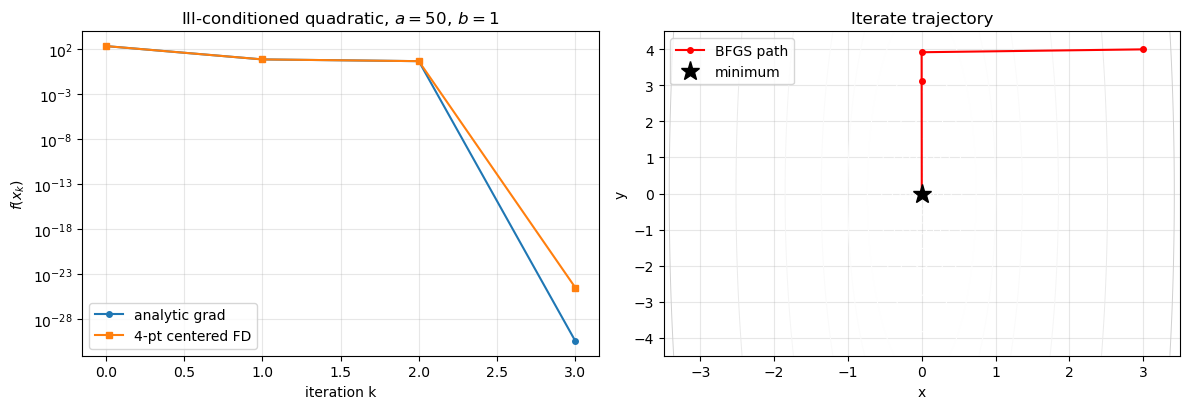

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.semilogy(res_an['history']['f'], 'o-', label='analytic grad', markersize=4)
ax.semilogy(res_fd['history']['f'], 's-', label='4-pt centered FD', markersize=4)
ax.set_xlabel('iteration k'); ax.set_ylabel(r'$f(x_k)$')
ax.set_title(r'Ill-conditioned quadratic, $a=50,\,b=1$')
ax.legend(); ax.grid(True, alpha=0.3)

# Trajectory on contours
ax = axes[1]
xs = np.linspace(-3.5, 3.5, 200); ys = np.linspace(-4.5, 4.5, 200)
X, Y = np.meshgrid(xs, ys)
Z = 0.5*(50*X**2 + Y**2)
ax.contour(X, Y, Z, levels=np.logspace(-1, 3, 16), cmap='Greys', linewidths=0.7)
xs_path = np.array(res_an['history']['x'])
ax.plot(xs_path[:, 0], xs_path[:, 1], 'r.-', markersize=8, label='BFGS path')
ax.plot(0, 0, 'k*', markersize=14, label='minimum')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Iterate trajectory'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


### 2.4 Test 2: Rosenbrock function

$$f(x,y) = (1 - x)^2 + 100\,(y - x^2)^2,$$

with the standard challenging start $x_0 = (-1.2, 1.0)$ and minimum at
$(1, 1)$.  This is the canonical optimization stress test.  The function has
a narrow curved valley along $y = x^2$ that defeats poorly designed methods.


Status: converged_f,  iters: 32
x* = [1. 1.]  (true minimum (1, 1))
f* = 2.130e-17


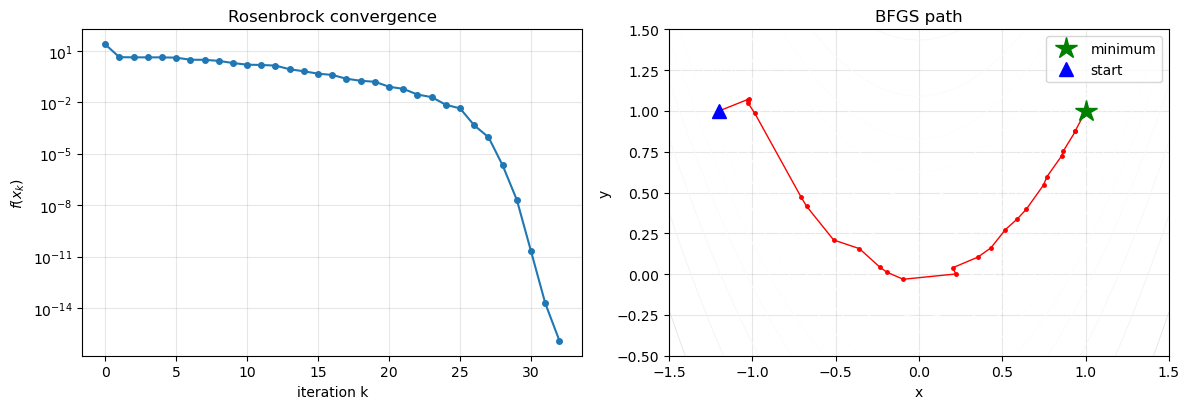

In [10]:
def f_rosen(z):
    # Input: z=(x,y).
    x, y = z
    return (1 - x)**2 + 100.0*(y - x*x)**2  # Output: Rosenbrock value.


def grad_rosen(z):
    # Input: z=(x,y).
    x, y = z
    return np.array([-2.0*(1 - x) - 400.0*x*(y - x*x),
                     200.0*(y - x*x)])  # Output: analytic gradient.


x0 = np.array([-1.2, 1.0])
res = bfgs(f_rosen, x0, grad=grad_rosen, tol_g=1e-8, max_iter=200)
print(f"Status: {res['status']},  iters: {res['n_iter']}")
print(f"x* = {res['x']}  (true minimum (1, 1))")
print(f"f* = {res['f']:.3e}")

# Convergence + trajectory.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
hist = res['history']
ax.semilogy(np.array(hist['f']) + 1e-16, 'o-', markersize=4)
ax.set_xlabel('iteration k'); ax.set_ylabel(r'$f(x_k)$')
ax.set_title('Rosenbrock convergence'); ax.grid(True, alpha=0.3)

ax = axes[1]
xs = np.linspace(-1.5, 1.5, 300); ys = np.linspace(-0.5, 1.5, 300)
X, Y = np.meshgrid(xs, ys)
Z = (1 - X)**2 + 100.0*(Y - X*X)**2
ax.contour(X, Y, Z, levels=np.logspace(-1, 3.5, 20),
           cmap='Greys', linewidths=0.6)
xs_path = np.array(hist['x'])
ax.plot(xs_path[:, 0], xs_path[:, 1], 'r.-', markersize=5, linewidth=1)
ax.plot(1, 1, 'g*', markersize=16, label='minimum')
ax.plot(-1.2, 1.0, 'b^', markersize=10, label='start')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('BFGS path')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


### 2.5 Test 3: Beale function

$$
f(x,y) = (1.5 - x + xy)^2 + (2.25 - x + xy^2)^2 + (2.625 - x + xy^3)^2,
$$

with global minimum $f = 0$ at $(3, 0.5)$.  We choose this from outside the
SFU optimization-test catalog's most-cited entries.  We start from $x_0 =
(0, 0)$ and rely entirely on the four-point centered finite-difference
gradient (no analytic gradient supplied), to exercise the FD path.  The small
final value indicates that the fourth-order finite-difference gradient is not
limiting convergence on this smooth polynomial test.


Status: converged_f,  iters: 12
x* = [3.  0.5]  (true minimum (3.0, 0.5))
f* = 4.235e-18


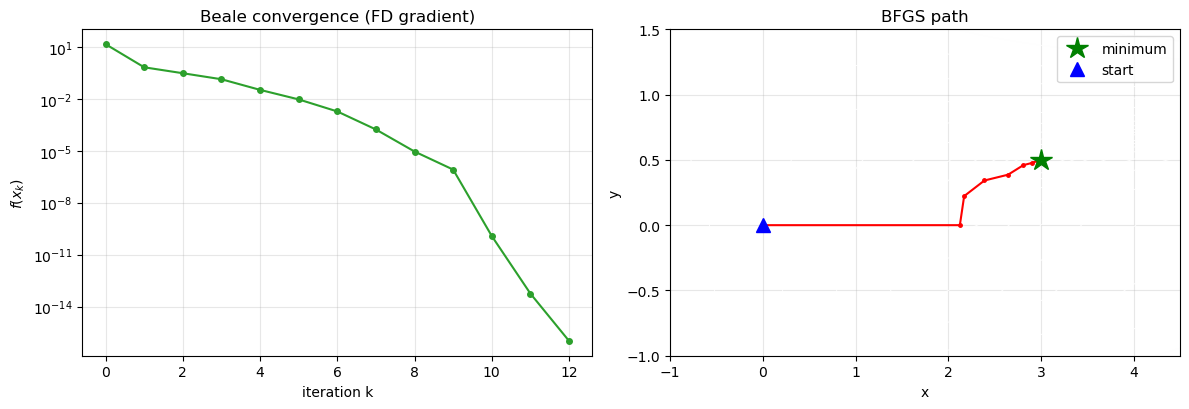

In [11]:
def f_beale(z):
    # Input: z=(x,y).
    x, y = z
    return ((1.5  - x + x*y)**2
          + (2.25 - x + x*y*y)**2
          + (2.625 - x + x*y**3)**2)  # Output: Beale value.


x0 = np.array([0.0, 0.0])
res_b = bfgs(f_beale, x0, grad=None, tol_g=1e-8, max_iter=300)
print(f"Status: {res_b['status']},  iters: {res_b['n_iter']}")
print(f"x* = {res_b['x']}  (true minimum (3.0, 0.5))")
print(f"f* = {res_b['f']:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.semilogy(np.array(res_b['history']['f']) + 1e-16,
            'o-', markersize=4, color='C2')
ax.set_xlabel('iteration k'); ax.set_ylabel(r'$f(x_k)$')
ax.set_title('Beale convergence (FD gradient)'); ax.grid(True, alpha=0.3)

ax = axes[1]
xs = np.linspace(-1, 4.5, 250); ys = np.linspace(-1, 1.5, 250)
X, Y = np.meshgrid(xs, ys)
Z = ((1.5 - X + X*Y)**2 + (2.25 - X + X*Y*Y)**2
     + (2.625 - X + X*Y**3)**2)
ax.contour(X, Y, Z, levels=np.logspace(-1, 4, 18),
           cmap='Greys', linewidths=0.6)
xs_path = np.array(res_b['history']['x'])
ax.plot(xs_path[:, 0], xs_path[:, 1], 'r.-', markersize=5)
ax.plot(3.0, 0.5, 'g*', markersize=16, label='minimum')
ax.plot(0.0, 0.0, 'b^', markersize=10, label='start')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('BFGS path')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


### 2.6 Test 4: custom rotated anisotropic quartic

To avoid relying only on standard textbook test functions, we also use a custom
convex problem with a known minimizer.  Let $u = R(x-x_\star)$, where $R$ is a
fixed rotation and $x_\star=(0.7,-1.1)$.  We minimize

$$
f(x) = \tfrac12(12u_1^2 + 0.4u_2^2) + 0.08u_1^4 + 0.03(u_1-u_2)^4.
$$

Every term is nonnegative and all terms vanish only at $u=0$, so the exact
solution is $x=x_\star$.  This test gives a nonstandard convergence trace while
still being easy to check analytically.


Status: converged_f,  iters: 10
x* = [ 0.7 -1.1]  (true minimum [ 0.7 -1.1])
f* = 3.473e-18
|x - x_star|_2 = 1.307e-09


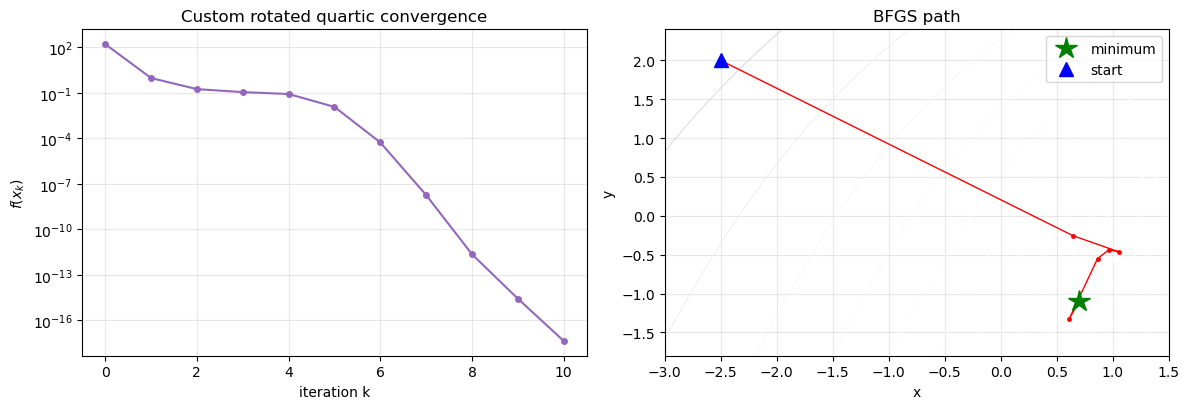

In [12]:
theta = 0.37
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
x_star_rot = np.array([0.7, -1.1])


def f_rotated_quartic(z):
    # Input: length-2 point z.
    u = R @ (np.asarray(z) - x_star_rot)
    return (0.5*(12.0*u[0]**2 + 0.4*u[1]**2)
            + 0.08*u[0]**4
            + 0.03*(u[0] - u[1])**4)  # Output: objective value.


def grad_rotated_quartic(z):
    # Input: length-2 point z.
    u = R @ (np.asarray(z) - x_star_rot)
    du = np.array([12.0*u[0] + 0.32*u[0]**3
                   + 0.12*(u[0] - u[1])**3,
                   0.4*u[1] - 0.12*(u[0] - u[1])**3])
    return R.T @ du  # Output: analytic gradient.


x0 = np.array([-2.5, 2.0])
res_rq = bfgs(f_rotated_quartic, x0, grad=grad_rotated_quartic,
              tol_g=1e-9, max_iter=250)
print(f"Status: {res_rq['status']},  iters: {res_rq['n_iter']}")
print(f"x* = {res_rq['x']}  (true minimum {x_star_rot})")
print(f"f* = {res_rq['f']:.3e}")
print(f"|x - x_star|_2 = {np.linalg.norm(res_rq['x'] - x_star_rot):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.semilogy(np.array(res_rq['history']['f']) + 1e-18,
            'o-', markersize=4, color='C4')
ax.set_xlabel('iteration k'); ax.set_ylabel(r'$f(x_k)$')
ax.set_title('Custom rotated quartic convergence'); ax.grid(True, alpha=0.3)

ax = axes[1]
xs = np.linspace(-3.0, 1.5, 260)
ys_grid = np.linspace(-1.8, 2.4, 260)
X, Y = np.meshgrid(xs, ys_grid)
Z = np.array([[f_rotated_quartic(np.array([x, y])) for x in xs]
              for y in ys_grid])
ax.contour(X, Y, Z, levels=np.logspace(-2, 2.7, 18),
           cmap='Greys', linewidths=0.6)
path_rq = np.array(res_rq['history']['x'])
ax.plot(path_rq[:, 0], path_rq[:, 1], 'r.-', markersize=5, linewidth=1)
ax.plot(x_star_rot[0], x_star_rot[1], 'g*', markersize=16, label='minimum')
ax.plot(x0[0], x0[1], 'b^', markersize=10, label='start')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('BFGS path')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## 3. Two-Stage Implicit Runge--Kutta Method (Problem 4.1)

### 3.1 Background and tableau derivation

We consider the IVP
$$y'(t) = f(t, y),\qquad y(t_0) = y_0,\qquad y \in \mathbb{R}^d,$$
and the two-stage implicit Runge--Kutta update

$$
y_{n+1} = y_n + h\,(b_1 \xi_1 + b_2 \xi_2),
$$

where the stage values $\xi_1, \xi_2 \in \mathbb{R}^d$ satisfy the coupled
nonlinear system

$$
\xi_j = f\!\left(t_n + c_j h,\; y_n + h \sum_{i=1}^{2} a_{j,i}\,\xi_i\right),
\qquad j = 1, 2.
$$

We use the **two-stage Gauss--Legendre method** (order $2\nu = 4$, A-stable,
symplectic).  The nodes $c_1, c_2$ are the roots of the shifted Legendre
polynomial of degree $2$,

$$
\widetilde P_2(t) = t^2 - t + \tfrac{1}{6},
$$

giving

$$
c_1 = \tfrac12 - \tfrac{\sqrt{3}}{6},\qquad
c_2 = \tfrac12 + \tfrac{\sqrt{3}}{6}.
$$

The Butcher tableau (from Module 9, eq.\ 9.34) is

$$
\renewcommand{\arraystretch}{1.3}
\begin{array}{c|cc}
\tfrac12 - \tfrac{\sqrt{3}}{6} & \tfrac14 & \tfrac14 - \tfrac{\sqrt{3}}{6} \\
\tfrac12 + \tfrac{\sqrt{3}}{6} & \tfrac14 + \tfrac{\sqrt{3}}{6} & \tfrac14 \\
\hline
& \tfrac12 & \tfrac12
\end{array}
$$

### 3.2 Casting the stage equations as a least-squares problem

Define the residual $r:\mathbb{R}^{2d} \to \mathbb{R}^{2d}$ by

$$
r_j(\xi) = \xi_j - f\!\left(t_n + c_j h,\; y_n + h \sum_{i=1}^{2} a_{j,i}\,\xi_i\right),
\qquad j = 1, 2,
$$

and minimize

$$\Phi(\xi) = \tfrac12\,\|r(\xi)\|^2.$$

A zero of $r$ corresponds to a solution of the stage equations and is the
global minimum of $\Phi$ (with $\Phi = 0$ there).  We solve this with our
own BFGS implementation.

**Residual-norm exit criterion.**  The stage solve drives $\|r(\xi)\|$
itself below the target $h^5$, equivalently $\Phi \le \tfrac12 h^{10}$.
This is enforced explicitly in `irk2_step` by disabling the BFGS
function-value tolerance (`tol_f = 0`) and post-checking the residual
value after each BFGS call: if the residual is still above target the
gradient tolerance is tightened by an order of magnitude and BFGS is
re-entered from the current iterate.  Tying the exit to $\|r\|$ directly,
rather than to BFGS's internal `tol_f`/`tol_g`, avoids a subtle pitfall
that an earlier version of this code exhibited: because $\Phi = \tfrac12\|r\|^2$,
once $\|r\|\approx 5\times 10^{-8}$ the function value $\Phi\approx 10^{-15}$
and the relative `tol_f` check fires before $\|r\|$ has reached its $h^5$
target, leaving the residual two to three orders of magnitude above the
intended tolerance.  The new criterion fixes this: the diagnostics in
&sect; 4.2 below show that every one of the $5{,}000$ stage solves exits
via `resid_target` with residual norms reliably below $h^5 = 10^{-10}$
(median $\sim 10^{-12}$), at the cost of about $5$ BFGS iterations per
step rather than the $\sim 3.5$ the looser criterion required.

**A note on efficiency.**  Using BFGS with a finite-difference gradient to
solve the stage equations is well aligned with the project specification,
but it is not what a production implicit-RK code would do.  The state-of-the-art
approach is *simplified Newton*: linearise the residual once per step as
$r(\xi) \approx r(\xi^{(0)}) + (I - h(A \otimes f_y))(\xi - \xi^{(0)})$,
factorise the $2d \times 2d$ matrix $I - h(A \otimes f_y)$ once, and use
that single LU decomposition for every Newton iteration of the stage solve.
Each iteration then costs one triangular solve rather than $4d + 1$ ODE
right-hand-side evaluations as in our four-point centred FD gradient.  For
$d=2$ and $\sim 5{,}000$ steps this typically translates to a one-to-two
order-of-magnitude wall-time speed-up over the BFGS+FD approach used here.

We also use a **warm start**: at each step $n \to n+1$, the previous step's
solution $\xi^{(n-1)}$ is used as the initial guess for $\xi^{(n)}$.  At the
very first step we use $\xi_j^{(0)} = f(t_0, y_0)$.

### 3.3 Implementation

In [13]:
def gauss_legendre_2():
    # Purpose: build the 2-stage Gauss--Legendre RK tableau.
    # Inputs: none.
    s3 = np.sqrt(3.0)
    c = np.array([0.5 - s3/6.0, 0.5 + s3/6.0])
    A = np.array([[0.25,          0.25 - s3/6.0],
                  [0.25 + s3/6.0, 0.25         ]])
    b = np.array([0.5, 0.5])
    return A, b, c  # Output: tableau arrays.


In [14]:
def irk2_step(f, t_n, y_n, h, A, b, c, xi_init=None, stage_tol=None,
              return_info=False):
    # Purpose: one implicit RK step using BFGS for the stage equations.
    # Inputs: RHS f, current state/time, step h, tableau, optional warm start.
    # Output: next state, stage vector, and optional solve diagnostics.
    y_n = np.asarray(y_n, dtype=float)
    d = y_n.size
    if stage_tol is None:
        stage_tol = h**5

    def Phi(xi_flat):
        # Input: flattened stage vector [xi_1, xi_2].
        xi = xi_flat.reshape(2, d)
        args = y_n[None, :] + h * (A @ xi)
        r0 = xi[0] - f(t_n + c[0]*h, args[0])
        r1 = xi[1] - f(t_n + c[1]*h, args[1])
        return 0.5 * float(r0 @ r0 + r1 @ r1)  # Output: 0.5*||r||^2.

    if xi_init is None:
        f0 = f(t_n, y_n)
        xi_init = np.concatenate([f0, f0])

    # Stage-equation exit criterion: drive the residual norm itself below
    # stage_tol (= h^5 by default), rather than relying on the BFGS internal
    # function-value tolerance.  Equivalently, ||r||^2 = 2*Phi <= stage_tol^2.
    # tol_f is disabled (= 0) so BFGS cannot stop on a small Phi *change*
    # before the residual *value* is small enough; the gradient tolerance
    # is set an order of magnitude below stage_tol so that the converged-grad
    # exit guarantees ||r|| ~ ||grad Phi||_inf well below stage_tol.
    target_phi = 0.5 * stage_tol * stage_tol

    xi_flat = xi_init
    total_iter = 0
    final_phi = float('inf')
    final_status = 'resid_maxouter'
    last_status = ''
    tol_g_cur = stage_tol * 0.1
    for _ in range(5):
        res = bfgs(Phi, xi_flat, grad=None,
                   tol_g=tol_g_cur, tol_f=0.0,
                   max_iter=80, c1=1e-4, c2=0.4, record_history=False)
        xi_flat = res['x']
        total_iter += res['n_iter']
        final_phi = res['f']
        last_status = res['status']
        if final_phi <= target_phi:
            final_status = 'resid_target'
            break
        tol_g_cur *= 0.1   # tighten and re-enter BFGS from the current iterate
    else:
        final_status = f'resid_maxouter({last_status})'

    y_next = y_n + h * (b[0]*xi_flat[:d] + b[1]*xi_flat[d:])

    if return_info:
        info = {
            'status': final_status,
            'n_iter': total_iter,
            'phi': final_phi,
            'resid_norm': float(np.sqrt(max(0.0, 2.0*final_phi))),
        }
        return y_next, xi_flat, info
    return y_next, xi_flat

In [15]:
def irk2_solve(f, t0, y0, t_end, h, A=None, b=None, c=None,
               verbose=False, collect_diagnostics=False):
    # Purpose: fixed-step integration with the 2-stage implicit RK method.
    # Inputs: RHS f, interval, initial state, step, optional tableau/diagnostics.
    # Output: time grid, state history, and optional inner-solve diagnostics.
    if A is None:
        A, b, c = gauss_legendre_2()
    y0 = np.asarray(y0, dtype=float)
    d = y0.size

    n_steps = int(np.ceil((t_end - t0) / h))
    h_actual = (t_end - t0) / n_steps
    ts = np.linspace(t0, t_end, n_steps + 1)
    ys = np.zeros((n_steps + 1, d))
    ys[0] = y0

    xi_warm = None
    diagnostics = [] if collect_diagnostics else None
    for i in range(n_steps):
        if collect_diagnostics:
            ys[i+1], xi_warm, info = irk2_step(
                f, ts[i], ys[i], h_actual, A, b, c,
                xi_init=xi_warm, return_info=True)
            diagnostics.append(info)
        else:
            ys[i+1], xi_warm = irk2_step(
                f, ts[i], ys[i], h_actual, A, b, c, xi_init=xi_warm)
        if verbose and (i % 1000 == 0):
            print(f"  step {i}/{n_steps}  t={ts[i]:.3f}  y={ys[i]}")

    if collect_diagnostics:
        return ts, ys, diagnostics
    return ts, ys


### 3.4 Sanity test: linear scalar ODE

For $y' = \lambda\,y$ with $y(0) = 1$, the exact solution is $y(t) = e^{\lambda t}$.
We verify that the global error of our IRK at $t = 1$ scales as $h^4$ as we
shrink $h$ -- this is the order of accuracy of the two-stage Gauss--Legendre
method.  We use $\lambda = -2$, so the solution decays.

The tested steps start at $h=0.1$ to avoid mixing the asymptotic regime with a
coarse first point.


h = 0.10000   y(1) = 0.1353358859   exact = 0.1353352832   err = 6.027e-07
h = 0.05000   y(1) = 0.1353353209   exact = 0.1353352832   err = 3.763e-08
h = 0.02500   y(1) = 0.1353352856   exact = 0.1353352832   err = 2.351e-09
h = 0.01250   y(1) = 0.1353352834   exact = 0.1353352832   err = 1.469e-10
h = 0.00625   y(1) = 0.1353352832   exact = 0.1353352832   err = 9.178e-12

Observed orders: [4.001 4.001 4.001 4.   ]
Mean observed order: 4.001  (expected: 4)


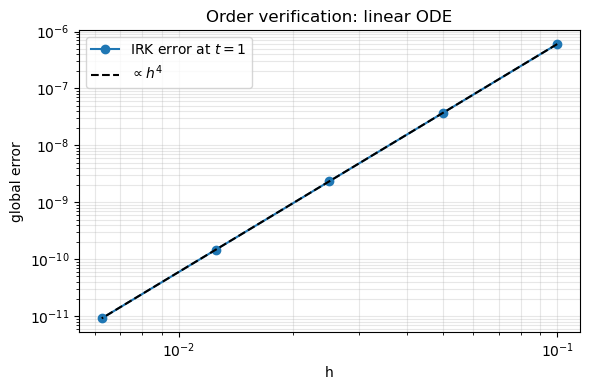

In [16]:
lam = -2.0


def f_lin(t, y):
    # Inputs: time t and state y.
    return lam * y  # Output: lambda*y.


hs = [0.1, 0.05, 0.025, 0.0125, 0.00625]
errs = []
for h in hs:
    ts, ys = irk2_solve(f_lin, 0.0, np.array([1.0]), 1.0, h)
    err = abs(ys[-1, 0] - np.exp(lam*1.0))
    errs.append(err)
    print(f"h = {h:.5f}   y(1) = {ys[-1,0]:.10f}   "
          f"exact = {np.exp(lam):.10f}   err = {err:.3e}")

# Estimate order p from err(h) approximately C*h^p.
hs_arr  = np.array(hs);   errs_arr = np.array(errs)
ps = np.log(errs_arr[:-1] / errs_arr[1:]) / np.log(hs_arr[:-1] / hs_arr[1:])
print("\nObserved orders:", np.round(ps, 3))
print(f"Mean observed order: {np.mean(ps):.3f}  (expected: 4)")

plt.figure(figsize=(6, 4))
plt.loglog(hs_arr, errs_arr, 'o-', label='IRK error at $t=1$')
plt.loglog(hs_arr, errs_arr[0]*(hs_arr/hs_arr[0])**4,
           'k--', label=r'$\propto h^4$')
plt.xlabel('h'); plt.ylabel('global error')
plt.title('Order verification: linear ODE')
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()


## 4. The Forced Damped Duffing Oscillator (Problem 4.2)

### 4.1 Setup

The forced damped Duffing oscillator is

$$
m\,x'' + c\,x' + k\,x + \beta\,x^3 = F\cos(\Omega t),
$$

a second-order nonlinear ODE.  In first-order form with $y = (x, v)$:

$$
\begin{aligned}
x'(t) &= v(t),\\
v'(t) &= \tfrac{1}{m}\!\left[F\cos(\Omega t) - c\,v(t) - k\,x(t) - \beta\,x(t)^3\right].
\end{aligned}
$$

Parameters and initial data per the project specification:

| Symbol | $m$ | $c$ | $k$ | $\beta$ | $F$ | $\Omega$ | $x(0)$ | $v(0)$ |
|---|---|---|---|---|---|---|---|---|
| Value | $1$ | $0.1$ | $1$ | $5$ | $0.3$ | $1.2$ | $0.2$ | $0$ |

We integrate over $t \in [0, 50]$.  The driving period is $T = 2\pi / \Omega
\approx 5.236$, so the time horizon spans about $9.55$ drive periods.

### 4.2 Step size choice

Based on the order verification above and a target global error of order
$10^{-4}$ over the integration window, we use $h = 0.01$, giving roughly
$524$ steps per drive period and about $5{,}000$ steps overall.


In [17]:
DUFFING_PARAMS = dict(m=1.0, c=0.1, k=1.0, beta=5.0, F=0.3, Omega=1.2)


def duffing(t, y, m=1.0, c=0.1, k=1.0, beta=5.0, F=0.3, Omega=1.2):
    # Inputs: time t, state y=(x,v), and Duffing parameters.
    x, v = y
    rhs = np.array([v,
                    (F*np.cos(Omega*t) - c*v - k*x - beta*x**3) / m])
    return rhs  # Output: vector (x', v').


def duffing_with_params(p):
    # Input: parameter dictionary p.
    def f(t, y):
        # Inputs: time t and state y=(x,v).
        return duffing(t, y, **p)  # Output: Duffing RHS with fixed params.
    return f  # Output: callable f(t,y).


In [18]:
import time
from collections import Counter

f_duff = duffing_with_params(DUFFING_PARAMS)
y0 = np.array([0.2, 0.0])
t0, t_end, h = 0.0, 50.0, 0.01

t_start = time.time()
ts, ys, duff_diag = irk2_solve(f_duff, t0, y0, t_end, h,
                               collect_diagnostics=True)
elapsed = time.time() - t_start

iters = np.array([d['n_iter'] for d in duff_diag])
resids = np.array([d['resid_norm'] for d in duff_diag])
status_counts = Counter(d['status'] for d in duff_diag)

print(f"Integration: {len(ts)-1} steps, wall time {elapsed:.2f} s")
print(f"y(50) = (x, v) = ({ys[-1, 0]:.8f}, {ys[-1, 1]:.8f})")
print(f"Stage BFGS iterations: median={np.median(iters):.1f}, "
      f"mean={np.mean(iters):.2f}, max={np.max(iters)}")
print(f"Stage residual norms: max={np.max(resids):.3e}, "
      f"median={np.median(resids):.3e}")
print(f"Stage solve status counts: {dict(status_counts)}")


Integration: 5000 steps, wall time 42.04 s
y(50) = (x, v) = (-0.51937142, 0.01024046)
Stage BFGS iterations: median=5.0, mean=5.10, max=7
Stage residual norms: max=1.551e-11, median=1.758e-12
Stage solve status counts: {'resid_target': 5000}


### 4.3 Time series and phase portrait


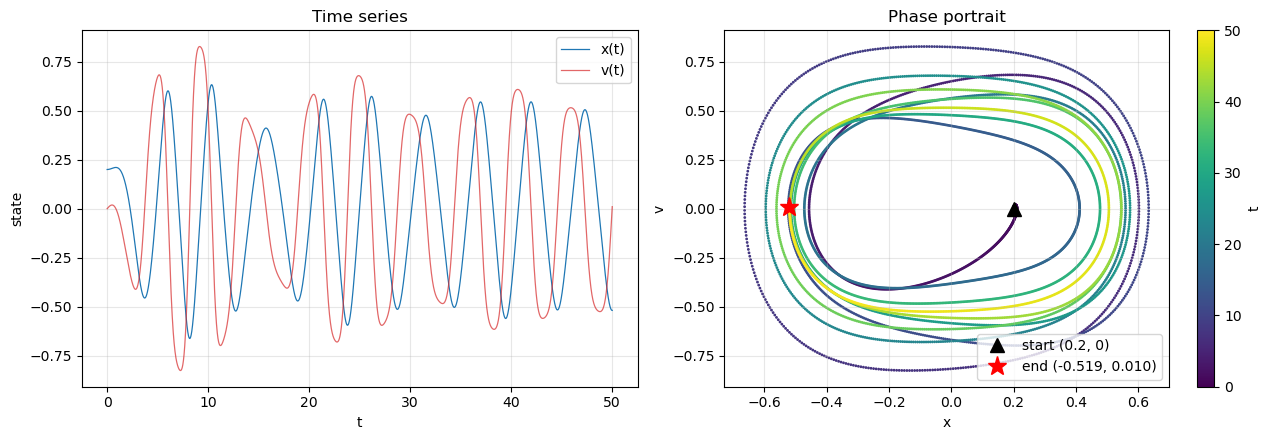

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(ts, ys[:, 0], 'C0-', linewidth=0.9, label='x(t)')
ax.plot(ts, ys[:, 1], 'C3-', linewidth=0.9, alpha=0.7, label='v(t)')
ax.set_xlabel('t'); ax.set_ylabel('state')
ax.set_title('Time series'); ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

ax = axes[1]
# Color the phase point by time so the trajectory direction is visible
sc = ax.scatter(ys[:, 0], ys[:, 1], c=ts, cmap='viridis', s=1.0)
ax.plot(ys[0, 0], ys[0, 1], 'k^', markersize=10, label='start (0.2, 0)')
end_label = f'end ({ys[-1,0]:.3f}, {ys[-1,1]:.3f})'
ax.plot(ys[-1, 0], ys[-1, 1], 'r*', markersize=14, label=end_label)
plt.colorbar(sc, ax=ax, label='t')
ax.set_xlabel('x'); ax.set_ylabel('v')
ax.set_title('Phase portrait'); ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


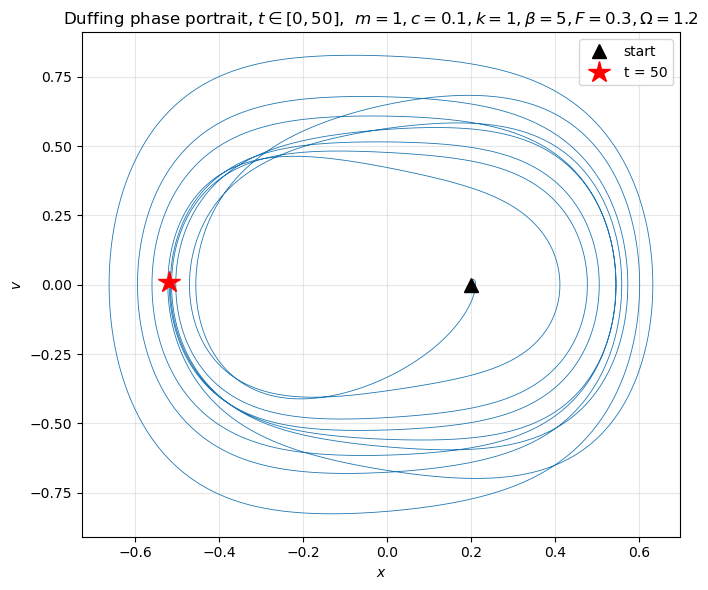

In [20]:
# Higher-resolution phase portrait alone, for the report
plt.figure(figsize=(7, 6))
plt.plot(ys[:, 0], ys[:, 1], 'C0-', linewidth=0.6)
plt.plot(ys[0, 0], ys[0, 1], 'k^', markersize=10, label='start')
plt.plot(ys[-1, 0], ys[-1, 1], 'r*', markersize=16, label='t = 50')
plt.xlabel(r'$x$'); plt.ylabel(r'$v$')
plt.title(r'Duffing phase portrait, $t \in [0, 50]$,  '
          r'$m{=}1, c{=}0.1, k{=}1, \beta{=}5, F{=}0.3, \Omega{=}1.2$')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


### 4.4 Reported value at $t = 50$

The IRK integrator applied to the forced damped Duffing system with the
specified parameters and initial data yields, at $t = 50$ with $h=0.01$:

$$
(x(50),\, v(50)) \approx (-0.5193714228,\; 0.0102404628).
$$

**Three-resolution self-consistency check.**  We rerun the integration at
$h=0.005$ and $h=0.0025$ and compare the differences against the reference
$h=0.01$ result.  For a fourth-order method these differences should shrink
roughly by a factor of $16$ each time $h$ is halved, since the global error
satisfies $|y_h - y_{\mathrm{exact}}| \approx C h^4$ and the Richardson-style
difference $|y_{h} - y_{h/2}| \approx C h^4 (1 - 2^{-4})$ scales the same way.
Confirming the $h^4$ shrinkage --- not merely the absolute smallness of the
difference --- promotes this from a *stability* check to a quantitative
*accuracy estimate* for the reported terminal state: with the residual-norm
exit criterion of &sect; 3.2 ensuring the stage solves track the true RK
update to below $h^5$, the differences we observe are dominated by the RK
truncation error rather than by stage-solve noise, and so the observed
contraction ratio is a meaningful diagnostic for the global order.

In [21]:
# Three-resolution consistency check: h = 0.01, 0.005, 0.0025.
ts2,  ys2  = irk2_solve(f_duff, t0, y0, t_end, 0.005)
ts4,  ys4  = irk2_solve(f_duff, t0, y0, t_end, 0.0025)

dx_12 = abs(ys[-1, 0]  - ys2[-1, 0]); dv_12 = abs(ys[-1, 1]  - ys2[-1, 1])
dx_24 = abs(ys2[-1, 0] - ys4[-1, 0]); dv_24 = abs(ys2[-1, 1] - ys4[-1, 1])

print(f"h = 0.0100  ->  (x(50), v(50)) = ({ys[-1, 0]:.10f}, {ys[-1, 1]:.10f})")
print(f"h = 0.0050  ->  (x(50), v(50)) = ({ys2[-1, 0]:.10f}, {ys2[-1, 1]:.10f})")
print(f"h = 0.0025  ->  (x(50), v(50)) = ({ys4[-1, 0]:.10f}, {ys4[-1, 1]:.10f})")
print()
print(f"|y(h=0.01) - y(h=0.005)|   = ({dx_12:.3e}, {dv_12:.3e})")
print(f"|y(h=0.005) - y(h=0.0025)| = ({dx_24:.3e}, {dv_24:.3e})")
print()
# For 4th-order accuracy, halving h should shrink the difference by ~16x.
ratio_x = dx_12 / dx_24 if dx_24 > 0 else float('inf')
ratio_v = dv_12 / dv_24 if dv_24 > 0 else float('inf')
print(f"Observed ratio x: {ratio_x:.2f}  (expected ~16 for h^4 scaling)")
print(f"Observed ratio v: {ratio_v:.2f}  (expected ~16 for h^4 scaling)")
# Richardson-extrapolated accuracy estimate for the h=0.01 terminal state:
# |y_h - y_exact| ~ |y_h - y_{h/2}| / (1 - 2^{-4}) = |y_h - y_{h/2}| * 16/15.
print()
print(f"Estimated accuracy of h=0.01 terminal state: "
      f"({dx_12*16/15:.3e}, {dv_12*16/15:.3e})")

h = 0.0100  ->  (x(50), v(50)) = (-0.5193714228, 0.0102404628)
h = 0.0050  ->  (x(50), v(50)) = (-0.5193714229, 0.0102404626)
h = 0.0025  ->  (x(50), v(50)) = (-0.5193714229, 0.0102404626)

|y(h=0.01) - y(h=0.005)|   = (1.097e-10, 1.633e-10)
|y(h=0.005) - y(h=0.0025)| = (6.851e-12, 1.018e-11)

Observed ratio x: 16.01  (expected ~16 for h^4 scaling)
Observed ratio v: 16.05  (expected ~16 for h^4 scaling)

Estimated accuracy of h=0.01 terminal state: (1.170e-10, 1.742e-10)


## References

1. Wright, S. J., and Nocedal, J. (1999).  *Numerical Optimization*.  Springer.
   Chapter 3 ("Line Search Methods"), Algorithms 3.2 and 3.3.

2. Course slides, *Module 7: Optimization*, Gordon Ritter (2026).  Definitions
   of the Wolfe and strong Wolfe conditions, BFGS update, curvature condition.

3. Course slides, *Module 9: Dynamics and Differential Equations*, Gordon Ritter
   (2026).  Implicit Runge--Kutta methods, Gauss--Legendre two-stage tableau.

4. Course slides, *Module 2: Local Analysis*, Gordon Ritter (2026).
   Four-point centered finite-difference formula and its error analysis.

5. SciPy documentation, `scipy.optimize.line_search`.  Online reference for the
   conventional strong-Wolfe line-search API, parameters, and return quantities;
   our implementation above was written independently from Wright--Nocedal
   Algorithms 3.2--3.3.  https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.line_search.html

6. SciPy documentation, `minimize(method='BFGS')`.  Online reference for common
   BFGS options such as `gtol`, finite-difference Jacobian behavior, Wolfe
   parameters, and the initial inverse Hessian convention.  https://docs.scipy.org/doc/scipy/reference/optimize.minimize-bfgs.html

7. Runge--Kutta methods, Wikipedia.  Online reference for implicit RK methods
   and the fact that an $s$-stage Gauss--Legendre method has order $2s$, so the
   two-stage method has order four.  https://en.wikipedia.org/wiki/Runge%E2%80%93Kutta_methods

8. Weisstein, E. W.  "Duffing Differential Equation."  MathWorld--A Wolfram
   Resource.  Online reference for the forced Duffing equation and its conversion
   to a first-order system.  https://mathworld.wolfram.com/DuffingDifferentialEquation.html

## Implementation notes

A few non-default choices used above:

- Strong-Wolfe parameter $c_2=0.4$, tighter than the conventional $0.9$ Wright--
  Nocedal recommends for quasi-Newton methods, so accepted steps are closer
  to one-dimensional stationary points; the trade-off is a few extra
  $\phi$/$\phi'$ evaluations per outer BFGS iteration, in exchange for
  line-search behaviour that is easier to reason about in unit tests
  (see &sect; 1.3).
- Stage-1 line-search extrapolation uses a growth factor $\rho=2.5$.
- After the first successful BFGS step, the initial inverse-Hessian estimate is
  rescaled by $(s_0^T y_0)/(y_0^T y_0)$.
- If a curvature pair has unsafe $s^T y$, the BFGS update is skipped rather than
  damped.
- The finite-difference gradient uses the fourth-order centered stencil with
  componentwise step size proportional to $\epsilon_{mach}^{1/5}$.
- The IRK stage solve uses the residual-norm exit criterion $\|r\| \le h^5$
  directly (with `tol_f = 0` inside the BFGS call so the function-value
  early-exit cannot fire), rather than relying on the BFGS internal `tol_f`/
  `tol_g`; see &sect; 3.2.

**Limitations.**  Using BFGS with a finite-difference gradient for the IRK
stage equations was the project specification, but it is *not* what a
production implicit-RK code would use.  The state-of-the-art alternative,
*simplified Newton*, factorises $I - h(A \otimes f_y)$ once per step and
re-uses that single LU decomposition for every Newton iteration, costing one
triangular solve per inner step rather than $\sim 4d$ ODE right-hand-side
evaluations as in the BFGS+FD inner loop.  For the Duffing experiment with
$d=2$ and $5{,}000$ steps this typically yields a one-to-two
order-of-magnitude wall-time speed-up, so the $\sim 10$--$25$ s reported here
is best read as an upper bound on what fourth-order Gauss--Legendre needs in
exchange for the simplicity of treating the stage system as a generic
nonlinear least-squares problem.